In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("cybersecurity_intrusion_data.csv")

print(df.head())
print(df.shape)

  session_id  network_packet_size protocol_type  login_attempts  \
0  SID_00001                  599           TCP               4   
1  SID_00002                  472           TCP               3   
2  SID_00003                  629           TCP               3   
3  SID_00004                  804           UDP               4   
4  SID_00005                  453           TCP               5   

   session_duration encryption_used  ip_reputation_score  failed_logins  \
0        492.983263             DES             0.606818              1   
1       1557.996461             DES             0.301569              0   
2         75.044262             DES             0.739164              2   
3        601.248835             DES             0.123267              0   
4        532.540888             AES             0.054874              1   

  browser_type  unusual_time_access  attack_detected  
0         Edge                    0                1  
1      Firefox                    0 

In [3]:
features = [
    "network_packet_size",
    "session_duration",
    "login_attempts",
    "failed_logins",
    "ip_reputation_score"
]

X = df[features].copy()

X = X.fillna(X.median(numeric_only=True))

print(X.head())

   network_packet_size  session_duration  login_attempts  failed_logins  \
0                  599        492.983263               4              1   
1                  472       1557.996461               3              0   
2                  629         75.044262               3              2   
3                  804        601.248835               4              0   
4                  453        532.540888               5              1   

   ip_reputation_score  
0             0.606818  
1             0.301569  
2             0.739164  
3             0.123267  
4             0.054874  


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [5]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X_scaled)

print(df["cluster"].value_counts())

cluster
1    4961
0    4576
Name: count, dtype: int64


In [6]:
cluster_scores = df.groupby("cluster")["failed_logins"].mean()

abnormal_cluster = cluster_scores.idxmax()

df["category"] = df["cluster"].apply(
    lambda x: "Abnormal" if x == abnormal_cluster else "Normal"
)

print(df[["cluster", "category"]].head(10))

   cluster  category
0        1    Normal
1        1    Normal
2        0  Abnormal
3        1    Normal
4        1    Normal
5        0  Abnormal
6        1    Normal
7        0  Abnormal
8        1    Normal
9        1    Normal


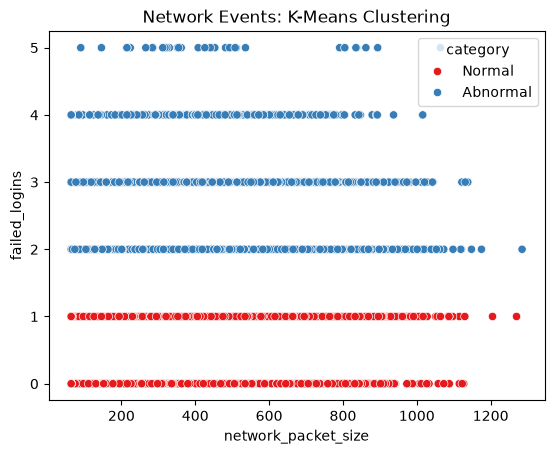

In [7]:
sns.scatterplot(
    data=df,
    x="network_packet_size",
    y="failed_logins",
    hue="category",
    palette="Set1"
)

plt.title("Network Events: K-Means Clustering")
plt.show()

In [8]:
print(df["category"].value_counts())

print("\nSample classified events:")
print(df[features + ["category"]].head(10))

category
Normal      4961
Abnormal    4576
Name: count, dtype: int64

Sample classified events:
   network_packet_size  session_duration  login_attempts  failed_logins  \
0                  599        492.983263               4              1   
1                  472       1557.996461               3              0   
2                  629         75.044262               3              2   
3                  804        601.248835               4              0   
4                  453        532.540888               5              1   
5                  453        380.471550               5              2   
6                  815        728.107165               4              1   
7                  653         12.599906               3              3   
8                  406        542.558895               2              0   
9                  608        531.944107               6              1   

   ip_reputation_score  category  
0             0.606818    Normal  
1       